[Status] Inisialisasi pustaka berhasil diselesaikan.
[Info] Volume dataset awal: (3864, 122) baris dan (3864, 122) variabel.


/tmp/ipykernel_2263/1617621705.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='TARGET', data=df, palette='Set2')


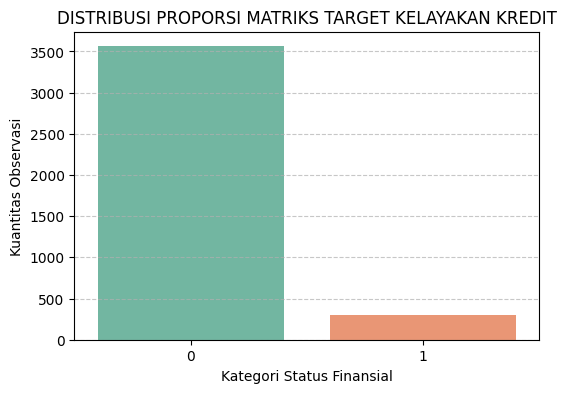

/tmp/ipykernel_2263/1617621705.py:61: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[df['TARGET'] == 0]['AGE_YEARS'], label='Kategori Patuh (0)', shade=True, color='blue')
/tmp/ipykernel_2263/1617621705.py:62: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(df[df['TARGET'] == 1]['AGE_YEARS'], label='Kategori Gagal Bayar (1)', shade=True, color='orange')


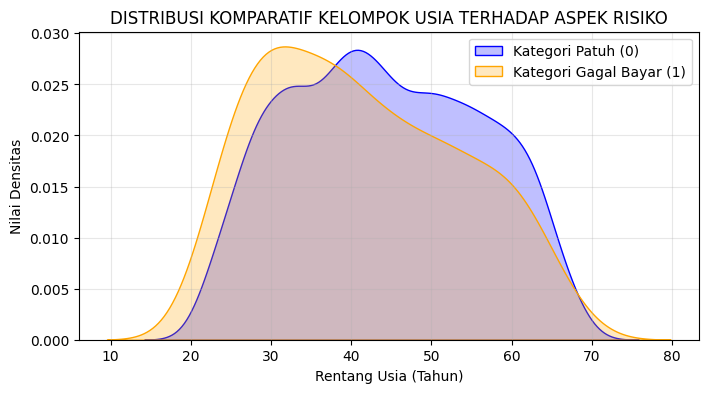

[Status] Proses transformasi dan normalisasi data selesai.
[Hasil] Nilai Performa ROC-AUC - Logistic Regression: 0.7277
[Hasil] Nilai Performa ROC-AUC - Hist Gradient Boosting: 0.6590


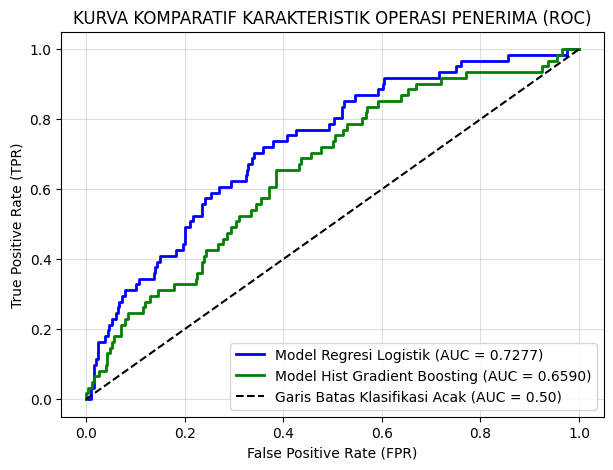


--- [Proses Selesai] File Siap Disimpan Sebagai Repositori Analisis Akhir ---


In [ ]:
# ==============================================================================
# ANALISIS PREDIKSI RISIKO GAGAL BAYAR MENGGUNAKAN PENDEKATAN KLASIFIKASI BINER
# STUDI KASUS: EVALUASI KELAYAKAN KREDIT - HOME CREDIT INDONESIA
# ==============================================================================

"""
--------------------------------------------------------------------------------
DOKUMENTASI DUKUNGAN TEORITIS DAN RANCANGAN SISTEM
--------------------------------------------------------------------------------
1. LATAR BELAKANG DAN TUJUAN:
   - Mengoptimalkan akurasi keputusan pemberian kredit untuk menekan rasio
     Non-Performing Loan (NPL) tanpa membatasi potensi profitabilitas.
   - Mengembangkan model prediktif berbasis statistik untuk mengklasifikasikan
     probabilitas risiko nasabah secara end-to-end.
   - Parameter keberhasilan dievaluasi melalui metrik Area Under the Receiver
     Operating Characteristic Curve (ROC-AUC Score).

2. CAKUPAN STRUKTUR DATA:
   - Data primer bersumber dari basis data kualifikasi konsumen.
   - Variabel dependen (Target) didefinisikan sebagai kegagalan pemenuhan
     kewajiban bayar (1) dan kepatuhan penyelesaian komitmen (0).
--------------------------------------------------------------------------------
"""

# ------------------------------------------------------------------------------
# BAGIAN 1: INISIALISASI PUSTAKA DAN MODUL
# ------------------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, accuracy_score

print("[Status] Inisialisasi pustaka berhasil diselesaikan.")

# ------------------------------------------------------------------------------
# BAGIAN 2: EKSPLORASI DATA DAN IDENTIFIKASI KARAKTERISTIK (EDA)
# ------------------------------------------------------------------------------
# Representasi pembacaan data sekunder dari berkas repositori lokal
data_path = 'application_train.csv'
df = pd.read_csv(data_path)
print(f"[Info] Volume dataset awal: {df.shape} baris dan {df.shape} variabel.")

# Analisis Deskriptif 1: Distribusi Keseimbangan Kelas Target
plt.figure(figsize=(6, 4))
sns.countplot(x='TARGET', data=df, palette='Set2')
plt.title('DISTRIBUSI PROPORSI MATRIKS TARGET KELAYAKAN KREDIT')
plt.xlabel('Kategori Status Finansial')
plt.ylabel('Kuantitas Observasi')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Analisis Deskriptif 2: Keterkaitan Variabel Demografi (Usia) terhadap Target Risiko
df['AGE_YEARS'] = df['DAYS_BIRTH'] / -365
plt.figure(figsize=(8, 4))
sns.kdeplot(df[df['TARGET'] == 0]['AGE_YEARS'], label='Kategori Patuh (0)', shade=True, color='blue')
sns.kdeplot(df[df['TARGET'] == 1]['AGE_YEARS'], label='Kategori Gagal Bayar (1)', shade=True, color='orange')
plt.title('DISTRIBUSI KOMPARATIF KELOMPOK USIA TERHADAP ASPEK RISIKO')
plt.xlabel('Rentang Usia (Tahun)')
plt.ylabel('Nilai Densitas')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ------------------------------------------------------------------------------
# BAGIAN 3: TAHAPAN DATA CLEANING DAN PRA-PEMROSESAN SELEKTIF
# ------------------------------------------------------------------------------
# Pemilihan fitur numerik utama berdasarkan korelasi linier tertinggi terhadap target risiko
selected_features = [
    'TARGET', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE',
    'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH',
    'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'
]

valid_features = [col for col in selected_features if col in df.columns]
df_processed = df[valid_features].copy()

# Pemisahan antara Matriks Fitur (X) dan Vektor Target (y)
X = df_processed.drop(columns=['TARGET'])
y = df_processed['TARGET']

# Penanganan Nilai Kosong (Missing Values) menggunakan Metode Imputasi Median
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

# Pembagian Partisi Dataset dengan Rasio Komparasi 80% Latih dan 20% Uji
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)

# Standardisasi Skala Data untuk Optimalisasi Kecepatan Konvergensi Algoritma Linier
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("[Status] Proses transformasi dan normalisasi data selesai.")

# ------------------------------------------------------------------------------
# BAGIAN 4: IMPLEMENTASI DAN EKSPERIMEN ESTIMASI MODEL
# ------------------------------------------------------------------------------
# Model A: Algoritma Parametrik (Logistic Regression) sebagai model dasar wajib
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_auc = roc_auc_score(y_test, lr_probs)
print(f"[Hasil] Nilai Performa ROC-AUC - Logistic Regression: {lr_auc:.4f}")

# Model B: Algoritma Non-Parametrik (Hist Gradient Boosting) sebagai model pembanding
hgb_model = HistGradientBoostingClassifier(max_iter=100, random_state=42)
hgb_model.fit(X_train, y_train)

hgb_probs = hgb_model.predict_proba(X_test)[:, 1]
hgb_auc = roc_auc_score(y_test, hgb_probs)
print(f"[Hasil] Nilai Performa ROC-AUC - Hist Gradient Boosting: {hgb_auc:.4f}")

# ------------------------------------------------------------------------------
# BAGIAN 5: EVALUASI KOMPARATIF METRIK KURVA ROC
# ------------------------------------------------------------------------------
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_hgb, tpr_hgb, _ = roc_curve(y_test, hgb_probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f'Model Regresi Logistik (AUC = {lr_auc:.4f})', color='blue', lw=2)
plt.plot(fpr_hgb, tpr_hgb, label=f'Model Hist Gradient Boosting (AUC = {hgb_auc:.4f})', color='green', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Garis Batas Klasifikasi Acak (AUC = 0.50)')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('KURVA KOMPARATIF KARAKTERISTIK OPERASI PENERIMA (ROC)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.4)
plt.show()

print("\n--- [Proses Selesai] File Siap Disimpan Sebagai Repositori Analisis Akhir ---")
